# COM7022 Machine Learning: E-commerce Product Clustering

**.

This notebook uses the supplied sales dataset to prepare product features, compare K-Means, agglomerative hierarchical clustering and DBSCAN, validate the results, and profile the resulting product groups. Keep the CSV beside this notebook when running it.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

## 2. Load and inspect the supplied dataset

In [2]:
# Search common notebook locations and prompt for a CSV in Google Colab when needed.
candidate_paths = [
    Path("Sales-[5444].csv"),
    Path("upload/Sales-[5444].csv"),
    Path("/content/Sales-[5444].csv"),
]
data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        data_path = next((Path(name) for name in uploaded if name.lower().endswith(".csv")), None)
    except ImportError:
        data_path = None

if data_path is None or not data_path.exists():
    raise FileNotFoundError("Place Sales-[5444].csv beside this notebook, in an upload folder, or upload it when prompted in Google Colab.")

raw = pd.read_csv(data_path)
print(f"Loaded: {data_path}")
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(raw.head())
missing_summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(1),
})
display(missing_summary)

Loaded: Sales-[5444].csv
Rows: 1,000 | Columns: 10


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


,dtype,missing,missing_pct
Item_Name,str,1,0.1
details,str,0,0.0
Catatory,str,3,0.3
price,float64,5,0.5
priceWithCurrency,str,1,0.1
available,float64,111,11.1
text,str,3,0.3
sold,float64,8,0.8
lastUpdated,str,53,5.3
itemLocation,str,0,0.0


## 3. Prepare the fields used for clustering

In [3]:
# Parse numeric values and recover fields embedded in the listing text where possible.
data = raw.copy()
data.columns = data.columns.str.strip()

for column in ["price", "available", "sold"]:
    if column in data.columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")

if "price" in data.columns and "priceWithCurrency" in data.columns:
    price_from_text = pd.to_numeric(
        data["priceWithCurrency"].astype("string").str.replace(r"[^0-9.]", "", regex=True),
        errors="coerce",
    )
    data["price"] = data["price"].fillna(price_from_text)

if "text" in data.columns:
    listing_text = data["text"].fillna("").astype(str)
    if "sold" in data.columns:
        sold_from_text = pd.to_numeric(
            listing_text.str.extract(r"([\d,]+)\s*sold", flags=re.IGNORECASE, expand=False).str.replace(",", "", regex=False),
            errors="coerce",
        )
        data["sold"] = data["sold"].fillna(sold_from_text)
    if "available" in data.columns:
        availability_text = listing_text.str.extract(r"([\d,]+)\s+available", flags=re.IGNORECASE, expand=False)
        availability_from_text = pd.to_numeric(availability_text.str.replace(",", "", regex=False), errors="coerce")
        # The text gives a lower-bound phrase, not an exact inventory count.
        availability_from_text = availability_from_text.mask(listing_text.str.contains(r"more than\s+10", case=False, na=False), 11)
        data["available"] = data["available"].fillna(availability_from_text)

rows_before_deduplication = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print(f"Exact duplicate rows removed: {rows_before_deduplication - len(data)}")

numeric_candidates = [column for column in ["price", "available", "sold"] if column in data.columns and data[column].notna().any()]
categorical_candidates = [column for column in ["Catatory", "Category", "category"] if column in data.columns]
if not categorical_candidates:
    categorical_candidates = [column for column in ["Item_Name"] if column in data.columns]

if not numeric_candidates:
    raise ValueError("No usable numeric clustering fields were found in the dataset.")
if not categorical_candidates:
    raise ValueError("No usable categorical clustering field was found in the dataset.")

category_column = categorical_candidates[0]
data[category_column] = data[category_column].fillna("Unknown").astype(str).str.strip().replace("", "Unknown")

# Log transformation reduces the influence of the strongly right-skewed sales and availability counts.
numeric_features = []
for column in numeric_candidates:
    if column in ["available", "sold"]:
        transformed_column = f"{column}_log1p"
        data[transformed_column] = np.log1p(data[column].clip(lower=0))
        numeric_features.append(transformed_column)
    else:
        numeric_features.append(column)

categorical_features = [category_column]
feature_columns = numeric_features + categorical_features
print("Selected clustering fields:", feature_columns)
print("Numeric fields are listing price and log-transformed sales/availability counts where present. The category is one-hot encoded. Item names, free-text descriptions, locations and update timestamps are excluded because they are identifiers, high-cardinality text, or time/location fields outside the selected product and sales comparison.")
display(data[feature_columns].describe(include="all").T)
display(data[numeric_features].isna().sum().rename("missing_before_imputation").to_frame())

Exact duplicate rows removed: 0
Selected clustering fields: ['price', 'available_log1p', 'sold_log1p', 'Catatory']
Numeric fields are listing price and log-transformed sales/availability counts where present. The category is one-hot encoded. Item names, free-text descriptions, locations and update timestamps are excluded because they are identifiers, high-cardinality text, or time/location fields outside the selected product and sales comparison.


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,1000.0,<NA>,<NA>,<NA>,46.4812,35.527862,3.0,22.99,35.71,59.0,259.09
available_log1p,891.0,NaN,NaN,NaN,2.287839,0.898068,1.098612,1.791759,2.397895,2.397895,6.736967
sold_log1p,994.0,NaN,NaN,NaN,4.298687,2.069074,0.693147,2.70805,3.931826,5.782282,10.89772
Catatory,1000,64,Eau de Toilette,444,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_before_imputation
price,0
available_log1p,109
sold_log1p,6


## 4. Impute, encode and scale features

In [4]:
# Impute missing values, normalize numeric inputs to [0, 1], and encode categories.
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", MinMaxScaler()),
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("encode", encoder),
        ]), categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)

X = np.asarray(preprocessor.fit_transform(data[feature_columns]), dtype=float)
feature_names = preprocessor.get_feature_names_out()
print(f"Prepared matrix: {X.shape[0]} products × {X.shape[1]} features")
print(f"All values finite after imputation and transformation: {np.isfinite(X).all()}")
print("MinMaxScaler performs feature normalization; category labels are one-hot encoded. Log1p limits the effect of extreme sales and availability values before scaling.")

Prepared matrix: 1000 products × 67 features
All values finite after imputation and transformation: True
MinMaxScaler performs feature normalization; category labels are one-hot encoded. Log1p limits the effect of extreme sales and availability values before scaling.


## 5. Evaluation function and clustering model search

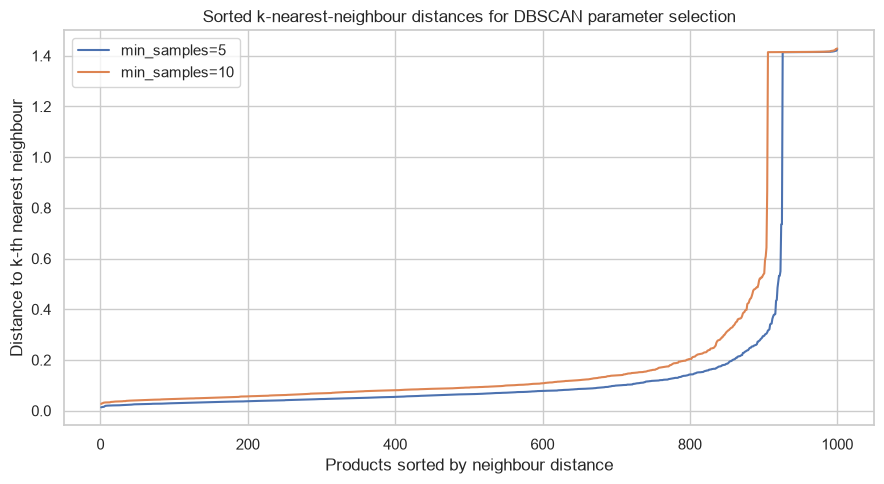

DBSCAN eps candidates from distance quantiles: [0.071, 0.086, 0.099, 0.118, 0.121, 0.161, 0.185, 0.312, 1.414, 1.415, 1.416]


,model,algorithm,parameters,n_clusters,noise_pct,coverage_pct,metric_scope,silhouette,calinski_harabasz,davies_bouldin,inertia
13,Agglomerative_ward_k6,Agglomerative hierarchical,"{'n_clusters': 6, 'linkage': 'ward'}",6,0.0,100.0,all products,0.6668,578.4431,1.2121,NaN
12,Agglomerative_ward_k5,Agglomerative hierarchical,"{'n_clusters': 5, 'linkage': 'ward'}",5,0.0,100.0,all products,0.6449,607.0050,1.2026,NaN
11,Agglomerative_ward_k4,Agglomerative hierarchical,"{'n_clusters': 4, 'linkage': 'ward'}",4,0.0,100.0,all products,0.6130,638.5507,1.1789,NaN
10,Agglomerative_ward_k3,Agglomerative hierarchical,"{'n_clusters': 3, 'linkage': 'ward'}",3,0.0,100.0,all products,0.5766,737.1739,1.1675,NaN
17,Agglomerative_ward_k10,Agglomerative hierarchical,"{'n_clusters': 10, 'linkage': 'ward'}",10,0.0,100.0,all products,0.5245,470.6795,1.1984,NaN
16,Agglomerative_ward_k9,Agglomerative hierarchical,"{'n_clusters': 9, 'linkage': 'ward'}",9,0.0,100.0,all products,0.5164,487.9474,1.2101,NaN
15,Agglomerative_ward_k8,Agglomerative hierarchical,"{'n_clusters': 8, 'linkage': 'ward'}",8,0.0,100.0,all products,0.5073,509.3082,1.2008,NaN
14,Agglomerative_ward_k7,Agglomerative hierarchical,"{'n_clusters': 7, 'linkage': 'ward'}",7,0.0,100.0,all products,0.4969,536.8216,1.1923,NaN
9,Agglomerative_ward_k2,Agglomerative hierarchical,"{'n_clusters': 2, 'linkage': 'ward'}",2,0.0,100.0,all products,0.4616,676.2045,0.9597,NaN
25,DBSCAN_eps0.118_min10,DBSCAN,"{'eps': 0.118, 'min_samples': 10}",5,27.4,72.6,clustered products only,0.7963,1816.0218,0.2547,NaN


In [5]:
# Scores for DBSCAN describe clustered products only; its noise points are reported separately.
def evaluate_labels(X_values, labels):
    labels = np.asarray(labels)
    assigned = labels != -1
    metric_X = X_values[assigned]
    metric_labels = labels[assigned]
    unique_labels = np.unique(metric_labels)
    has_noise = bool((~assigned).any())
    result = {
        "n_clusters": len(unique_labels),
        "noise_pct": round(float((~assigned).mean() * 100), 2),
        "coverage_pct": round(float(assigned.mean() * 100), 2),
        "metric_scope": "clustered products only" if has_noise else "all products",
        "silhouette": np.nan,
        "calinski_harabasz": np.nan,
        "davies_bouldin": np.nan,
    }
    if len(unique_labels) >= 2 and len(unique_labels) < len(metric_labels):
        result["silhouette"] = float(silhouette_score(metric_X, metric_labels))
        result["calinski_harabasz"] = float(calinski_harabasz_score(metric_X, metric_labels))
        result["davies_bouldin"] = float(davies_bouldin_score(metric_X, metric_labels))
    return result

models = {}
evaluation_rows = []

# Compare a common range of cluster counts for partition-based methods.
for k in range(2, min(11, len(data))):
    model_name = f"KMeans_k{k}"
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X)
    models[model_name] = {"model": model, "labels": labels, "algorithm": "K-Means", "parameters": {"n_clusters": k}}
    row = {"model": model_name, "algorithm": "K-Means", "parameters": str({"n_clusters": k}), **evaluate_labels(X, labels), "inertia": float(model.inertia_)}
    evaluation_rows.append(row)

for k in range(2, min(11, len(data))):
    model_name = f"Agglomerative_ward_k{k}"
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X)
    models[model_name] = {"model": model, "labels": labels, "algorithm": "Agglomerative hierarchical", "parameters": {"n_clusters": k, "linkage": "ward"}}
    row = {"model": model_name, "algorithm": "Agglomerative hierarchical", "parameters": str({"n_clusters": k, "linkage": "ward"}), **evaluate_labels(X, labels), "inertia": np.nan}
    evaluation_rows.append(row)

# Use a k-nearest-neighbour distance curve to choose data-driven DBSCAN eps candidates.
min_samples_options = [5, 10]
quantile_levels = [0.55, 0.65, 0.75, 0.85, 0.93, 0.98]
eps_candidates = set()
k_distance_curves = {}
for min_samples in min_samples_options:
    neighbors = NearestNeighbors(n_neighbors=min_samples, metric="euclidean").fit(X)
    distances, _ = neighbors.kneighbors(X)
    k_distances = np.sort(distances[:, -1])
    k_distance_curves[min_samples] = k_distances
    eps_candidates.update(round(float(np.quantile(k_distances, q)), 3) for q in quantile_levels)

eps_values = sorted(value for value in eps_candidates if value > 0)
if len(eps_values) < 3:
    eps_values = sorted(set(np.round(np.linspace(0.15, max(0.3, float(np.max(k_distance_curves[5]))), 6), 3)))

fig, axis = plt.subplots(figsize=(9, 5))
for min_samples, distances in k_distance_curves.items():
    axis.plot(np.arange(1, len(distances) + 1), distances, label=f"min_samples={min_samples}")
axis.set_title("Sorted k-nearest-neighbour distances for DBSCAN parameter selection")
axis.set_xlabel("Products sorted by neighbour distance")
axis.set_ylabel("Distance to k-th nearest neighbour")
axis.legend()
plt.tight_layout()
plt.show()
print("DBSCAN eps candidates from distance quantiles:", eps_values)

for eps in eps_values:
    for min_samples in min_samples_options:
        model_name = f"DBSCAN_eps{eps}_min{min_samples}"
        model = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean")
        labels = model.fit_predict(X)
        models[model_name] = {"model": model, "labels": labels, "algorithm": "DBSCAN", "parameters": {"eps": eps, "min_samples": min_samples}}
        row = {"model": model_name, "algorithm": "DBSCAN", "parameters": str({"eps": eps, "min_samples": min_samples}), **evaluate_labels(X, labels), "inertia": np.nan}
        evaluation_rows.append(row)

evaluation = pd.DataFrame(evaluation_rows)
display(evaluation.sort_values(["algorithm", "silhouette"], ascending=[True, False], na_position="last").round(4))

## 6. Compare validation measures

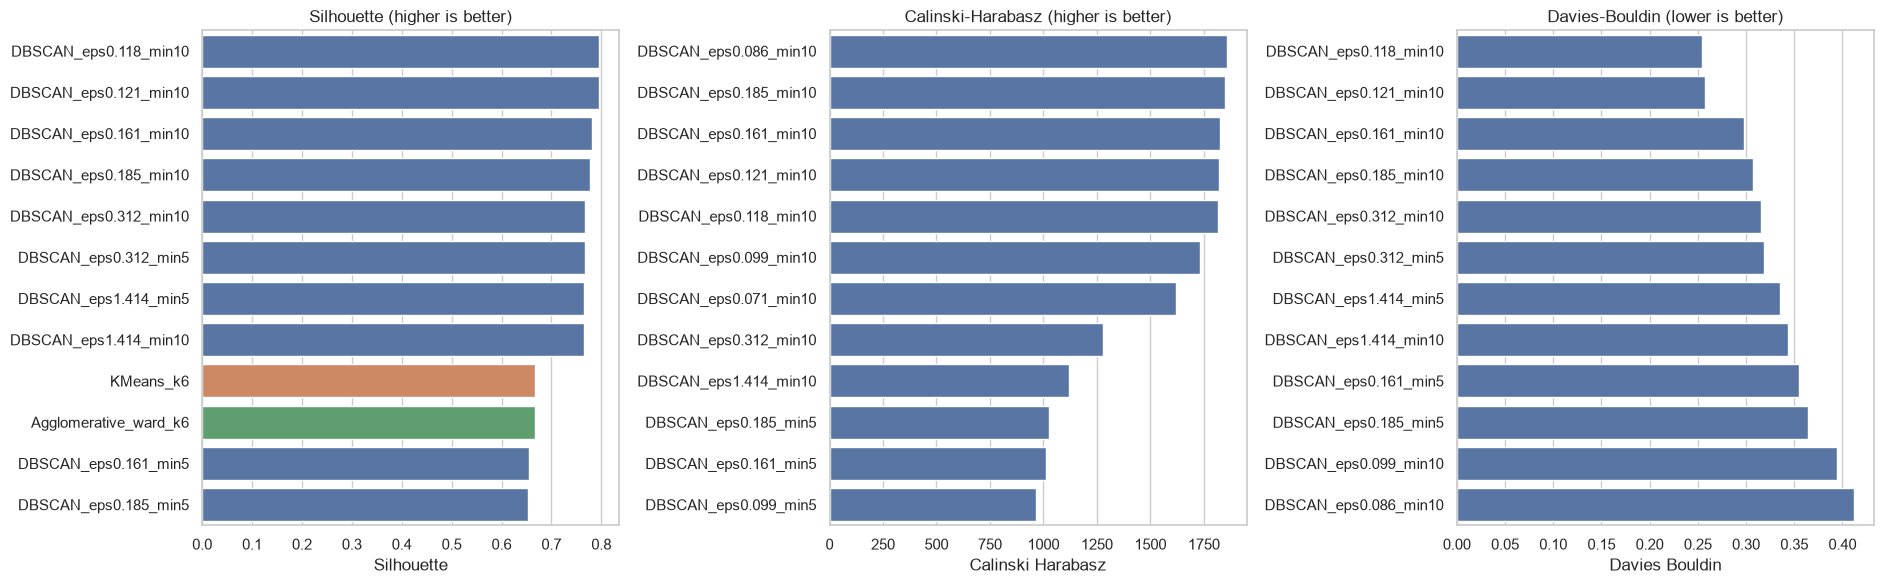

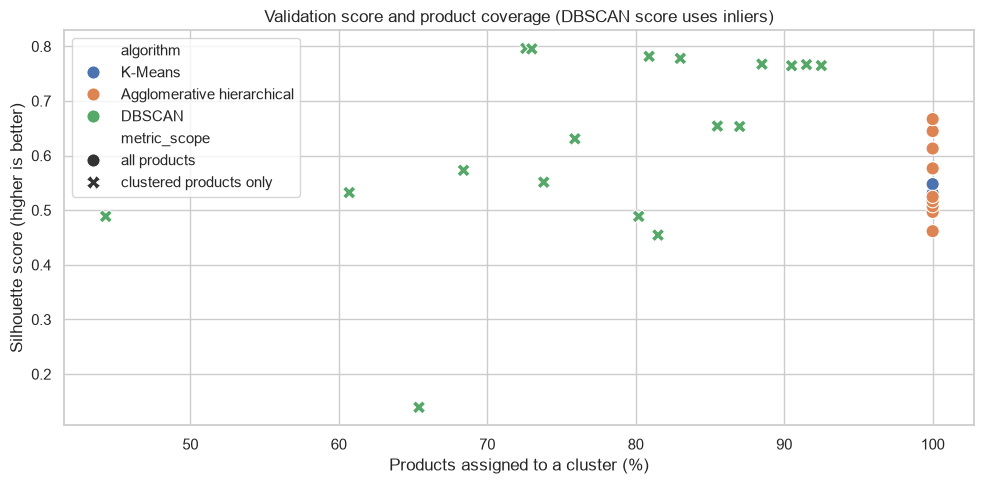

Compare DBSCAN's inlier-only scores separately from K-Means and hierarchical scores, which use all products.


In [6]:
# Plot the three validation measures; the metric_scope column identifies DBSCAN's inlier-only scores.
valid_evaluation = evaluation.dropna(subset=["silhouette"]).copy()
if valid_evaluation.empty:
    raise RuntimeError("No model produced at least two valid clusters. Review feature selection and clustering parameter ranges.")

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for axis, metric, title in zip(
    axes,
    ["silhouette", "calinski_harabasz", "davies_bouldin"],
    ["Silhouette (higher is better)", "Calinski-Harabasz (higher is better)", "Davies-Bouldin (lower is better)"],
):
    plot_data = valid_evaluation.sort_values(metric, ascending=(metric == "davies_bouldin")).head(12)
    sns.barplot(data=plot_data, x=metric, y="model", hue="algorithm", dodge=False, ax=axis)
    axis.set_title(title)
    axis.set_xlabel(metric.replace("_", " ").title())
    axis.set_ylabel("")
    if axis.legend_:
        axis.legend_.remove()
plt.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=valid_evaluation, x="coverage_pct", y="silhouette", hue="algorithm", style="metric_scope", s=90, ax=axis)
axis.set_title("Validation score and product coverage (DBSCAN score uses inliers)")
axis.set_xlabel("Products assigned to a cluster (%)")
axis.set_ylabel("Silhouette score (higher is better)")
plt.tight_layout()
plt.show()

print("Compare DBSCAN's inlier-only scores separately from K-Means and hierarchical scores, which use all products.")

## 7. Select the leading technical candidate

In [7]:
# Rank K-Means and hierarchical models using all products and all three validation metrics.
partition_evaluation = valid_evaluation[valid_evaluation["algorithm"] != "DBSCAN"].copy()
if partition_evaluation.empty:
    raise RuntimeError("No K-Means or hierarchical candidates have valid scores.")

partition_evaluation["silhouette_rank"] = partition_evaluation["silhouette"].rank(ascending=False, method="min")
partition_evaluation["calinski_rank"] = partition_evaluation["calinski_harabasz"].rank(ascending=False, method="min")
partition_evaluation["davies_rank"] = partition_evaluation["davies_bouldin"].rank(ascending=True, method="min")
partition_evaluation["mean_metric_rank"] = partition_evaluation[["silhouette_rank", "calinski_rank", "davies_rank"]].mean(axis=1)
best_partition_row = partition_evaluation.sort_values(
    ["mean_metric_rank", "silhouette", "davies_bouldin"],
    ascending=[True, False, True],
).iloc[0]
best_partition_name = best_partition_row["model"]
best_partition_labels = models[best_partition_name]["labels"]

# Compare each DBSCAN result with partition models on that DBSCAN result's identical inlier subset.
dbscan_comparisons = []
for model_name, model_result in models.items():
    if model_result["algorithm"] != "DBSCAN":
        continue
    labels = model_result["labels"]
    inlier_mask = labels != -1
    inlier_labels = labels[inlier_mask]
    cluster_count = len(np.unique(inlier_labels))
    coverage = float(inlier_mask.mean() * 100)
    if cluster_count < 2 or cluster_count >= len(inlier_labels):
        continue
    dbscan_silhouette = silhouette_score(X[inlier_mask], inlier_labels)
    comparison_scores = {}
    for partition_name, partition_result in models.items():
        if partition_result["algorithm"] == "DBSCAN":
            continue
        partition_inlier_labels = partition_result["labels"][inlier_mask]
        if len(np.unique(partition_inlier_labels)) >= 2:
            comparison_scores[partition_name] = silhouette_score(X[inlier_mask], partition_inlier_labels)
    if not comparison_scores:
        continue
    comparator_name = max(comparison_scores, key=comparison_scores.get)
    comparator_score = comparison_scores[comparator_name]
    dbscan_comparisons.append({
        "model": model_name,
        "coverage_pct": coverage,
        "n_clusters": cluster_count,
        "dbscan_inlier_silhouette": dbscan_silhouette,
        "best_partition_on_same_inliers": comparator_name,
        "partition_inlier_silhouette": comparator_score,
        "silhouette_gain": dbscan_silhouette - comparator_score,
    })

dbscan_comparison = pd.DataFrame(dbscan_comparisons)
display(partition_evaluation.sort_values("mean_metric_rank")[
    ["model", "algorithm", "silhouette", "calinski_harabasz", "davies_bouldin", "mean_metric_rank"]
].head(10).round(4))
if not dbscan_comparison.empty:
    display(dbscan_comparison.sort_values(["silhouette_gain", "coverage_pct"], ascending=[False, False]).round(4))

# Only consider DBSCAN as the lead model when it retains at least 80% of products and improves on a partition model on identical rows.
minimum_dbscan_coverage_pct = 80.0
minimum_silhouette_gain = 0.02
qualified_dbscan = pd.DataFrame()
if not dbscan_comparison.empty:
    qualified_dbscan = dbscan_comparison[
        (dbscan_comparison["coverage_pct"] >= minimum_dbscan_coverage_pct)
        & (dbscan_comparison["silhouette_gain"] >= minimum_silhouette_gain)
    ]

if not qualified_dbscan.empty:
    selected_model_name = qualified_dbscan.sort_values(
        ["silhouette_gain", "coverage_pct"], ascending=[False, False]
    ).iloc[0]["model"]
    selection_reason = "DBSCAN improves the silhouette over partition models on the same inlier rows and meets the stated coverage threshold."
else:
    selected_model_name = best_partition_name
    selection_reason = "No DBSCAN candidate met both the coverage and same-row improvement criteria; selected the strongest all-product partition candidate by mean rank across three validation measures."

selected_result = models[selected_model_name]
selected_labels = selected_result["labels"]
selected_evaluation = evaluation[evaluation["model"] == selected_model_name].iloc[0]
print("Selected candidate:", selected_model_name)
print("Algorithm:", selected_result["algorithm"])
print("Parameters:", selected_result["parameters"])
print(f"Silhouette: {selected_evaluation['silhouette']:.4f} | Coverage: {selected_evaluation['coverage_pct']:.1f}% | Clusters: {int(selected_evaluation['n_clusters'])}")
print("Selection basis:", selection_reason)
print("The 80% coverage and 0.02 silhouette-gain thresholds are explicit review settings, not requirements specified by the brief. Change them only with a stated business rationale.")

,model,algorithm,silhouette,calinski_harabasz,davies_bouldin,mean_metric_rank
10,Agglomerative_ward_k3,Agglomerative hierarchical,0.5766,737.1739,1.1675,3.6667
1,KMeans_k3,K-Means,0.5766,737.1739,1.1675,4.0000
11,Agglomerative_ward_k4,Agglomerative hierarchical,0.6130,638.5507,1.1789,5.0000
2,KMeans_k4,K-Means,0.6130,638.5507,1.1789,5.0000
0,KMeans_k2,K-Means,0.4616,676.2045,0.9597,7.0000
9,Agglomerative_ward_k2,Agglomerative hierarchical,0.4616,676.2045,0.9597,7.0000
12,Agglomerative_ward_k5,Agglomerative hierarchical,0.6449,607.0050,1.2026,7.6667
3,KMeans_k5,K-Means,0.6449,607.0050,1.2026,7.6667
13,Agglomerative_ward_k6,Agglomerative hierarchical,0.6668,578.4431,1.2121,9.0000
4,KMeans_k6,K-Means,0.6668,578.4431,1.2121,9.0000


,model,coverage_pct,n_clusters,dbscan_inlier_silhouette,best_partition_on_same_inliers,partition_inlier_silhouette,silhouette_gain
16,DBSCAN_eps1.414_min5,92.5,11,0.7648,KMeans_k6,0.7263,0.0385
14,DBSCAN_eps0.312_min5,91.5,10,0.7667,KMeans_k6,0.7344,0.0322
17,DBSCAN_eps1.414_min10,90.5,8,0.7646,KMeans_k6,0.7443,0.0203
15,DBSCAN_eps0.312_min10,88.5,7,0.7675,KMeans_k6,0.7582,0.0093
13,DBSCAN_eps0.185_min10,83.0,5,0.7780,KMeans_k5,0.7780,0.0000
11,DBSCAN_eps0.161_min10,80.9,5,0.7817,KMeans_k5,0.7817,0.0000
9,DBSCAN_eps0.121_min10,73.0,5,0.7955,KMeans_k5,0.7955,0.0000
7,DBSCAN_eps0.118_min10,72.6,5,0.7963,KMeans_k5,0.7963,0.0000
12,DBSCAN_eps0.185_min5,87.0,9,0.6533,KMeans_k6,0.7584,-0.1051
10,DBSCAN_eps0.161_min5,85.5,9,0.6541,KMeans_k6,0.7617,-0.1077


Selected candidate: DBSCAN_eps1.414_min5
Algorithm: DBSCAN
Parameters: {'eps': 1.414, 'min_samples': 5}
Silhouette: 0.7648 | Coverage: 92.5% | Clusters: 11
Selection basis: DBSCAN improves the silhouette over partition models on the same inlier rows and meets the stated coverage threshold.
The 80% coverage and 0.02 silhouette-gain thresholds are explicit review settings, not requirements specified by the brief. Change them only with a stated business rationale.


## 8. PCA visualisation

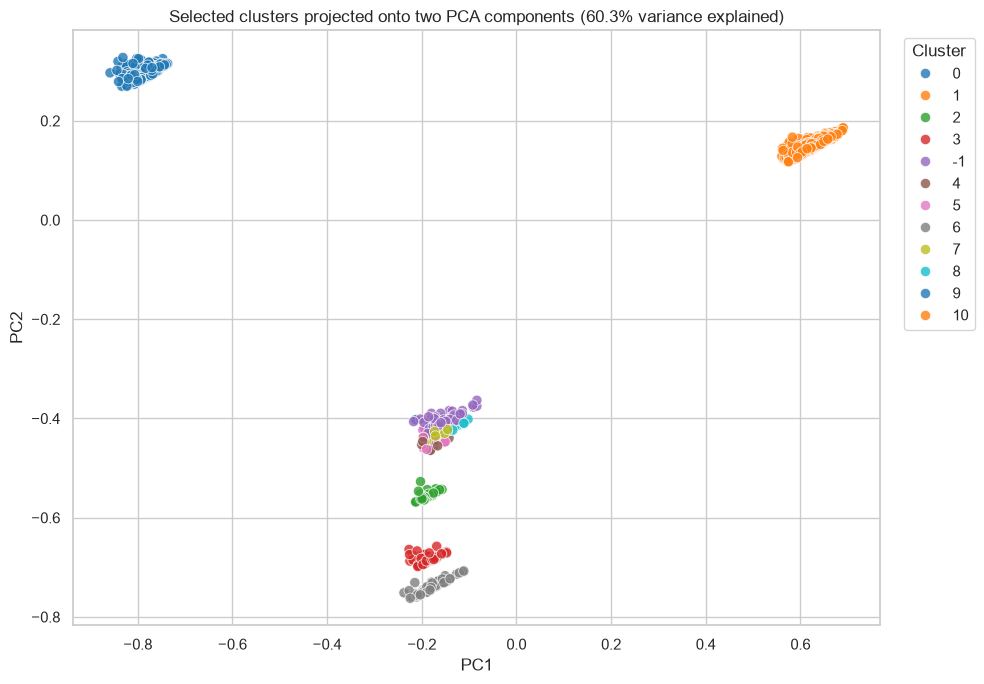

Variance explained by PC1 and PC2: [0.4508 0.1517]


In [8]:
# PCA is used for a two-dimensional view; models were fitted on the full prepared feature matrix.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
pca_variance = pca.explained_variance_ratio_.sum()

pca_frame = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "cluster": selected_labels.astype(str)})
fig, axis = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=pca_frame, x="PC1", y="PC2", hue="cluster", palette="tab10", s=55, alpha=0.8, ax=axis)
axis.set_title(f"Selected clusters projected onto two PCA components ({pca_variance:.1%} variance explained)")
axis.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Variance explained by PC1 and PC2:", np.round(pca.explained_variance_ratio_, 4))

## 9. Describe the clusters for the business scenario

,products,price,available,sold,estimated_sales_value_proxy,share_pct,dominant_category
cluster,,,,,,,
-1,75,26.1,10.0,30.0,1086.87,7.5,PARFUM
0,285,46.99,8.5,29.5,1392.3,28.5,Eau de Parfum
1,444,33.48,10.0,118.0,3801.0,44.4,Eau de Toilette
2,32,28.42,3.0,12.5,392.78,3.2,Fragrances
3,50,16.99,10.0,45.5,1316.06,5.0,Perfume
4,13,65.5,10.0,19.0,1160.91,1.3,Parfum
5,15,62.09,10.0,125.0,7532.69,1.5,Eau De Parfum
6,56,29.49,8.0,108.0,2623.9,5.6,Eau de Cologne
7,9,40.72,10.0,21.0,879.27,0.9,Eau De Toilette


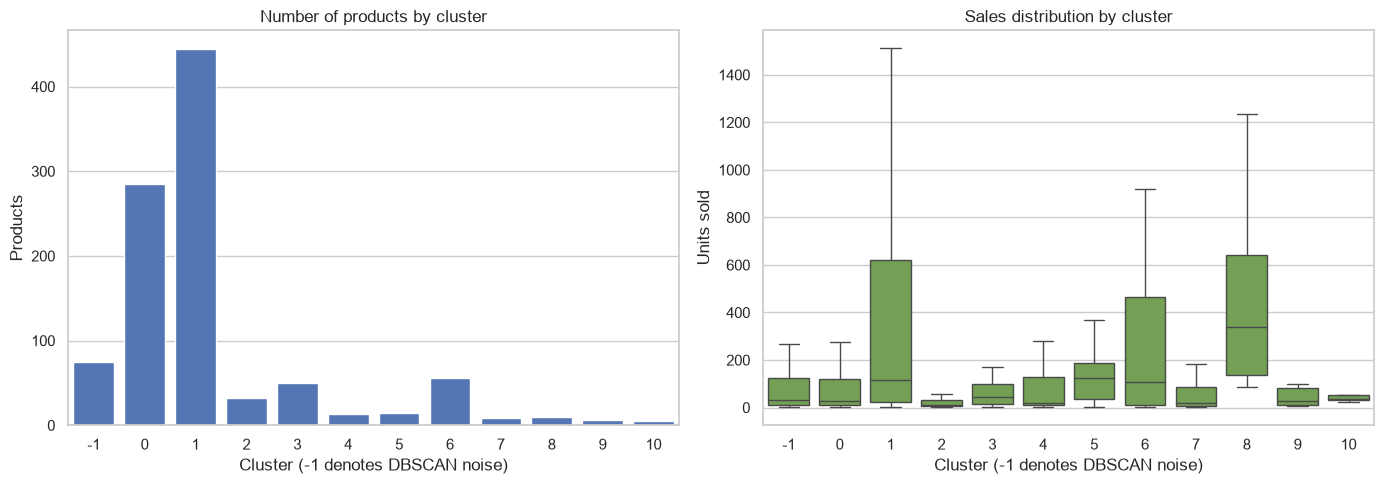

DBSCAN noise/outliers: 75 products (7.5% of the dataset); most common category: PARFUM; median listing price: $26.10; median sold: 30.
Cluster 0: 285 products (28.5% of the dataset); most common category: Eau de Parfum; median listing price: $46.99; median sold: 30.
Cluster 1: 444 products (44.4% of the dataset); most common category: Eau de Toilette; median listing price: $33.48; median sold: 118.
Cluster 2: 32 products (3.2% of the dataset); most common category: Fragrances; median listing price: $28.42; median sold: 12.
Cluster 3: 50 products (5.0% of the dataset); most common category: Perfume; median listing price: $16.99; median sold: 46.
Cluster 4: 13 products (1.3% of the dataset); most common category: Parfum; median listing price: $65.50; median sold: 19.
Cluster 5: 15 products (1.5% of the dataset); most common category: Eau De Parfum; median listing price: $62.09; median sold: 125.
Cluster 6: 56 products (5.6% of the dataset); most common category: Eau de Cologne; median li

,median,mean
cluster,,
-1,1086.87,28119.6
0,1392.3,12285.26
1,3801.0,43593.97
2,392.78,1114.9
3,1316.06,3369.26
4,1160.91,9402.2
5,7532.69,20154.54
6,2623.9,12751.29
7,879.27,2727.53


Estimated sales value is a rough listing-price × recorded-units-sold proxy, not verified revenue.
Interpret cluster profiles in context; a cluster association does not establish that price, category or availability caused sales performance.


In [9]:
# Summarize cluster size, dominant category, typical price and sales for business interpretation.
profile_data = data.copy()
profile_data["cluster"] = selected_labels
profile_data["estimated_sales_value_proxy"] = np.nan
if "price" in profile_data.columns and "sold" in profile_data.columns:
    profile_data["estimated_sales_value_proxy"] = profile_data["price"] * profile_data["sold"]

cluster_sizes = profile_data["cluster"].value_counts().sort_index().rename("products")
numeric_profile_columns = [column for column in ["price", "available", "sold", "estimated_sales_value_proxy"] if column in profile_data.columns]
cluster_profile = profile_data.groupby("cluster")[numeric_profile_columns].median().round(2)
cluster_profile.insert(0, "products", cluster_sizes)
cluster_profile["share_pct"] = (cluster_profile["products"] / len(profile_data) * 100).round(1)

if category_column in profile_data.columns:
    dominant_category = profile_data.groupby("cluster")[category_column].agg(lambda values: values.value_counts().index[0]).rename("dominant_category")
    cluster_profile = cluster_profile.join(dominant_category)

display(cluster_profile)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=cluster_sizes.index.astype(str), y=cluster_sizes.values, ax=axes[0], color="#4472C4")
axes[0].set_title("Number of products by cluster")
axes[0].set_xlabel("Cluster (-1 denotes DBSCAN noise)")
axes[0].set_ylabel("Products")

if "sold" in profile_data.columns:
    sns.boxplot(data=profile_data, x="cluster", y="sold", showfliers=False, ax=axes[1], color="#70AD47")
    axes[1].set_title("Sales distribution by cluster")
    axes[1].set_xlabel("Cluster (-1 denotes DBSCAN noise)")
    axes[1].set_ylabel("Units sold")
else:
    axes[1].axis("off")
plt.tight_layout()
plt.show()

# Produce short, data-based descriptions; these are descriptive associations, not causal claims.
for cluster_id, row in cluster_profile.iterrows():
    label = "DBSCAN noise/outliers" if cluster_id == -1 else f"Cluster {cluster_id}"
    parts = [f"{int(row['products'])} products ({row['share_pct']:.1f}% of the dataset)"]
    if "dominant_category" in row.index:
        parts.append(f"most common category: {row['dominant_category']}")
    if "price" in row.index and pd.notna(row["price"]):
        parts.append(f"median listing price: ${row['price']:.2f}")
    if "sold" in row.index and pd.notna(row["sold"]):
        parts.append(f"median sold: {row['sold']:.0f}")
    print(f"{label}: " + "; ".join(parts) + ".")

if "price" in profile_data.columns and "sold" in profile_data.columns:
    display(profile_data.groupby("cluster")["estimated_sales_value_proxy"].agg(["median", "mean"]).round(2))
    print("Estimated sales value is a rough listing-price × recorded-units-sold proxy, not verified revenue.")
print("Interpret cluster profiles in context; a cluster association does not establish that price, category or availability caused sales performance.")

## 10. Save reproducible outputs

In [10]:
# Save labels and model scores so the results can be inspected outside the notebook.
results = data.copy()
results["selected_cluster"] = selected_labels
results.to_csv("clustered_products_results.csv", index=False)
evaluation.to_csv("clustering_model_comparison.csv", index=False)
if not dbscan_comparison.empty:
    dbscan_comparison.to_csv("dbscan_same_rows_comparison.csv", index=False)

print("Saved: clustered_products_results.csv")
print("Saved: clustering_model_comparison.csv")
if not dbscan_comparison.empty:
    print("Saved: dbscan_same_rows_comparison.csv")
print("Notebook complete.")

Saved: clustered_products_results.csv
Saved: clustering_model_comparison.csv
Saved: dbscan_same_rows_comparison.csv
Notebook complete.
